# Tarea 3
Con base en los contenidos revisados en clase y utilizando la base de datos proporcionada (Base_Fuga_2025.xlsx), cada grupo deberá realizar un análisis exploratorio de datos que sirva como primer acercamiento a la comprension del problema. En esta tarea, se espera que apliquen las técnicas de preprocesamiento y visualizacion vistas en la sesión, identificando patrones, distribuciones y posibles relaciones entre variables.
Además, cada integrante del grupo deber ́a detectar al menos dos inconsistencias en la base de datos (por ejemplo, valores fuera de rango, duplicados, inconsistencias lógicas, errores tipográficos o
datos faltantes no justificados). Estas inconsistencias deben ser claramente descritas y asignadas al responsable que las detectó.

El análisis deberá ser entregado en un archivo Word (o formato compatible) por grupo, incluyendo: Identificación clara del responsable de cada inconsistencia detectada, breve descripción de las inconsistencias y su impacto potencial en el análisis y pantallazo del gr ́afico que muestra el problema.

COSAS A HACER, Mejorar el final y el RANKING de Variables

In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
from pandas.api.types import is_numeric_dtype
from scipy import stats
from scipy.stats import chi2_contingency
from google.colab import drive
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler, KBinsDiscretizer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.feature_selection import SelectKBest, f_classif
np.set_printoptions(suppress=True)

In [ ]:
# Acceder a Google Drive
drive.mount('/content/gdrive')
# Cargar Documento
ruta_data_set = '/content/gdrive/MyDrive/Proyecto BA G19/Entrega 3/Base_Fuga_2025.xlsx'
data_set = pd.read_excel(ruta_data_set, sheet_name='Entrenamiento')
# Estadística Descriptiva
data_set.describe(include='all').round(1)

Mounted at /content/gdrive


,CreditMes_T,CreditMes_T-1,CreditMes_T-2,NumTarjCred_T,NumTarjCred_T-1,NumTarjCred_T-2,Ingreso,Edad,NumTransWeb_T,NumTransWeb_T-1,...,MargenComp_T-3,MargenComp_T-4,MargenComp_T-5,MargenComp_T-6,Telefono,NivelEduc,Genero,EstCivil,Region,FUGA
count,5603.0,5605.0,5605.0,5598.0,5603.0,5605.0,5605.0,5605.0,5603.0,5603.0,...,5605.0,5603.0,5604.0,5605.0,5605,5602,5605,5603,5605,5605
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,4,3,4,1,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SI,UNI,M,CAS,RM,NF
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,5605,3627,3895,2960,5605,4889
mean,1021484.8,632812.1,583796.3,0.8,0.8,0.8,1223802.4,35.9,5.2,3.9,...,253053.6,253046.6,260956.4,195991.5,NaN,NaN,NaN,NaN,NaN,NaN
std,115216.5,127733.6,80016.5,0.7,0.7,0.7,562272.8,9.2,11.3,8.5,...,2472.4,2546.6,1653.4,3001.6,NaN,NaN,NaN,NaN,NaN,NaN
min,912650.0,500000.0,500000.0,0.0,0.0,0.0,-975950.0,15.0,0.0,0.0,...,100000.0,157840.0,183560.0,137500.0,NaN,NaN,NaN,NaN,NaN,NaN
25%,990500.0,597200.0,562100.0,0.0,0.0,0.0,890450.0,29.0,0.0,0.0,...,252840.0,252960.0,260800.0,195380.0,NaN,NaN,NaN,NaN,NaN,NaN
50%,997700.0,604850.0,566150.0,1.0,1.0,1.0,1057650.0,33.0,0.0,1.0,...,252960.0,253040.0,260880.0,195640.0,NaN,NaN,NaN,NaN,NaN,NaN
75%,1014800.0,623300.0,577400.0,1.0,1.0,1.0,1362600.0,41.0,6.0,5.0,...,253260.0,253320.0,261100.0,196420.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Definir la ruta donde quieres guardar el archivo en Google Drive
ruta_archivo = '/content/gdrive/MyDrive/Proyecto BA G19/Entrega 3/descripcion_estadistica.csv'  # Ajusta la ruta

# Guardar el DataFrame como CSV
descripcion = data_set.describe(include='all').round(1)
descripcion.to_csv(ruta_archivo, encoding='utf-8')

print(f"Tabla guardada en: {ruta_archivo}")

Tabla guardada en: /content/gdrive/MyDrive/Proyecto BA G19/Entrega 3/descripcion_estadistica.csv


A primera vista hay valores perdidos (nulos) e inconsistencias
*   Valores nulos
*   En Ingresos, el min es negativo.
*   En edad, el max es 131 y el min es 15 ()
*   NumTarjCred_T NumTarjCred_T-1 y NumTarjCred_T-2 max 9 tarjetas (preocupante)





In [ ]:
# Revisión de datos nulos.
data_set.isnull().sum()

,0
CreditMes_T,2
CreditMes_T-1,0
CreditMes_T-2,0
NumTarjCred_T,7
NumTarjCred_T-1,2
NumTarjCred_T-2,0
Ingreso,0
Edad,0
NumTransWeb_T,2
NumTransWeb_T-1,2


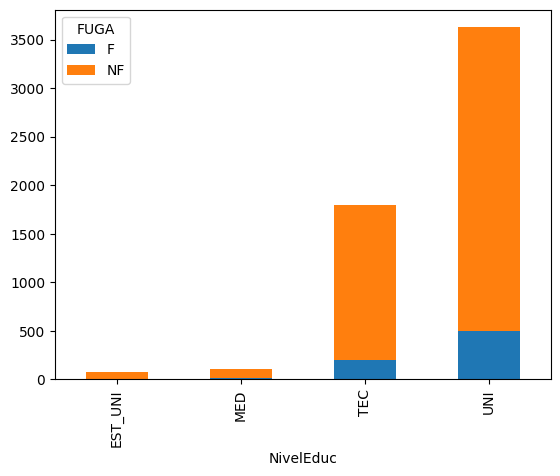

In [ ]:
data_set.groupby(['NivelEduc', 'FUGA']).size().unstack().plot.bar(stacked=True)
plt.show()

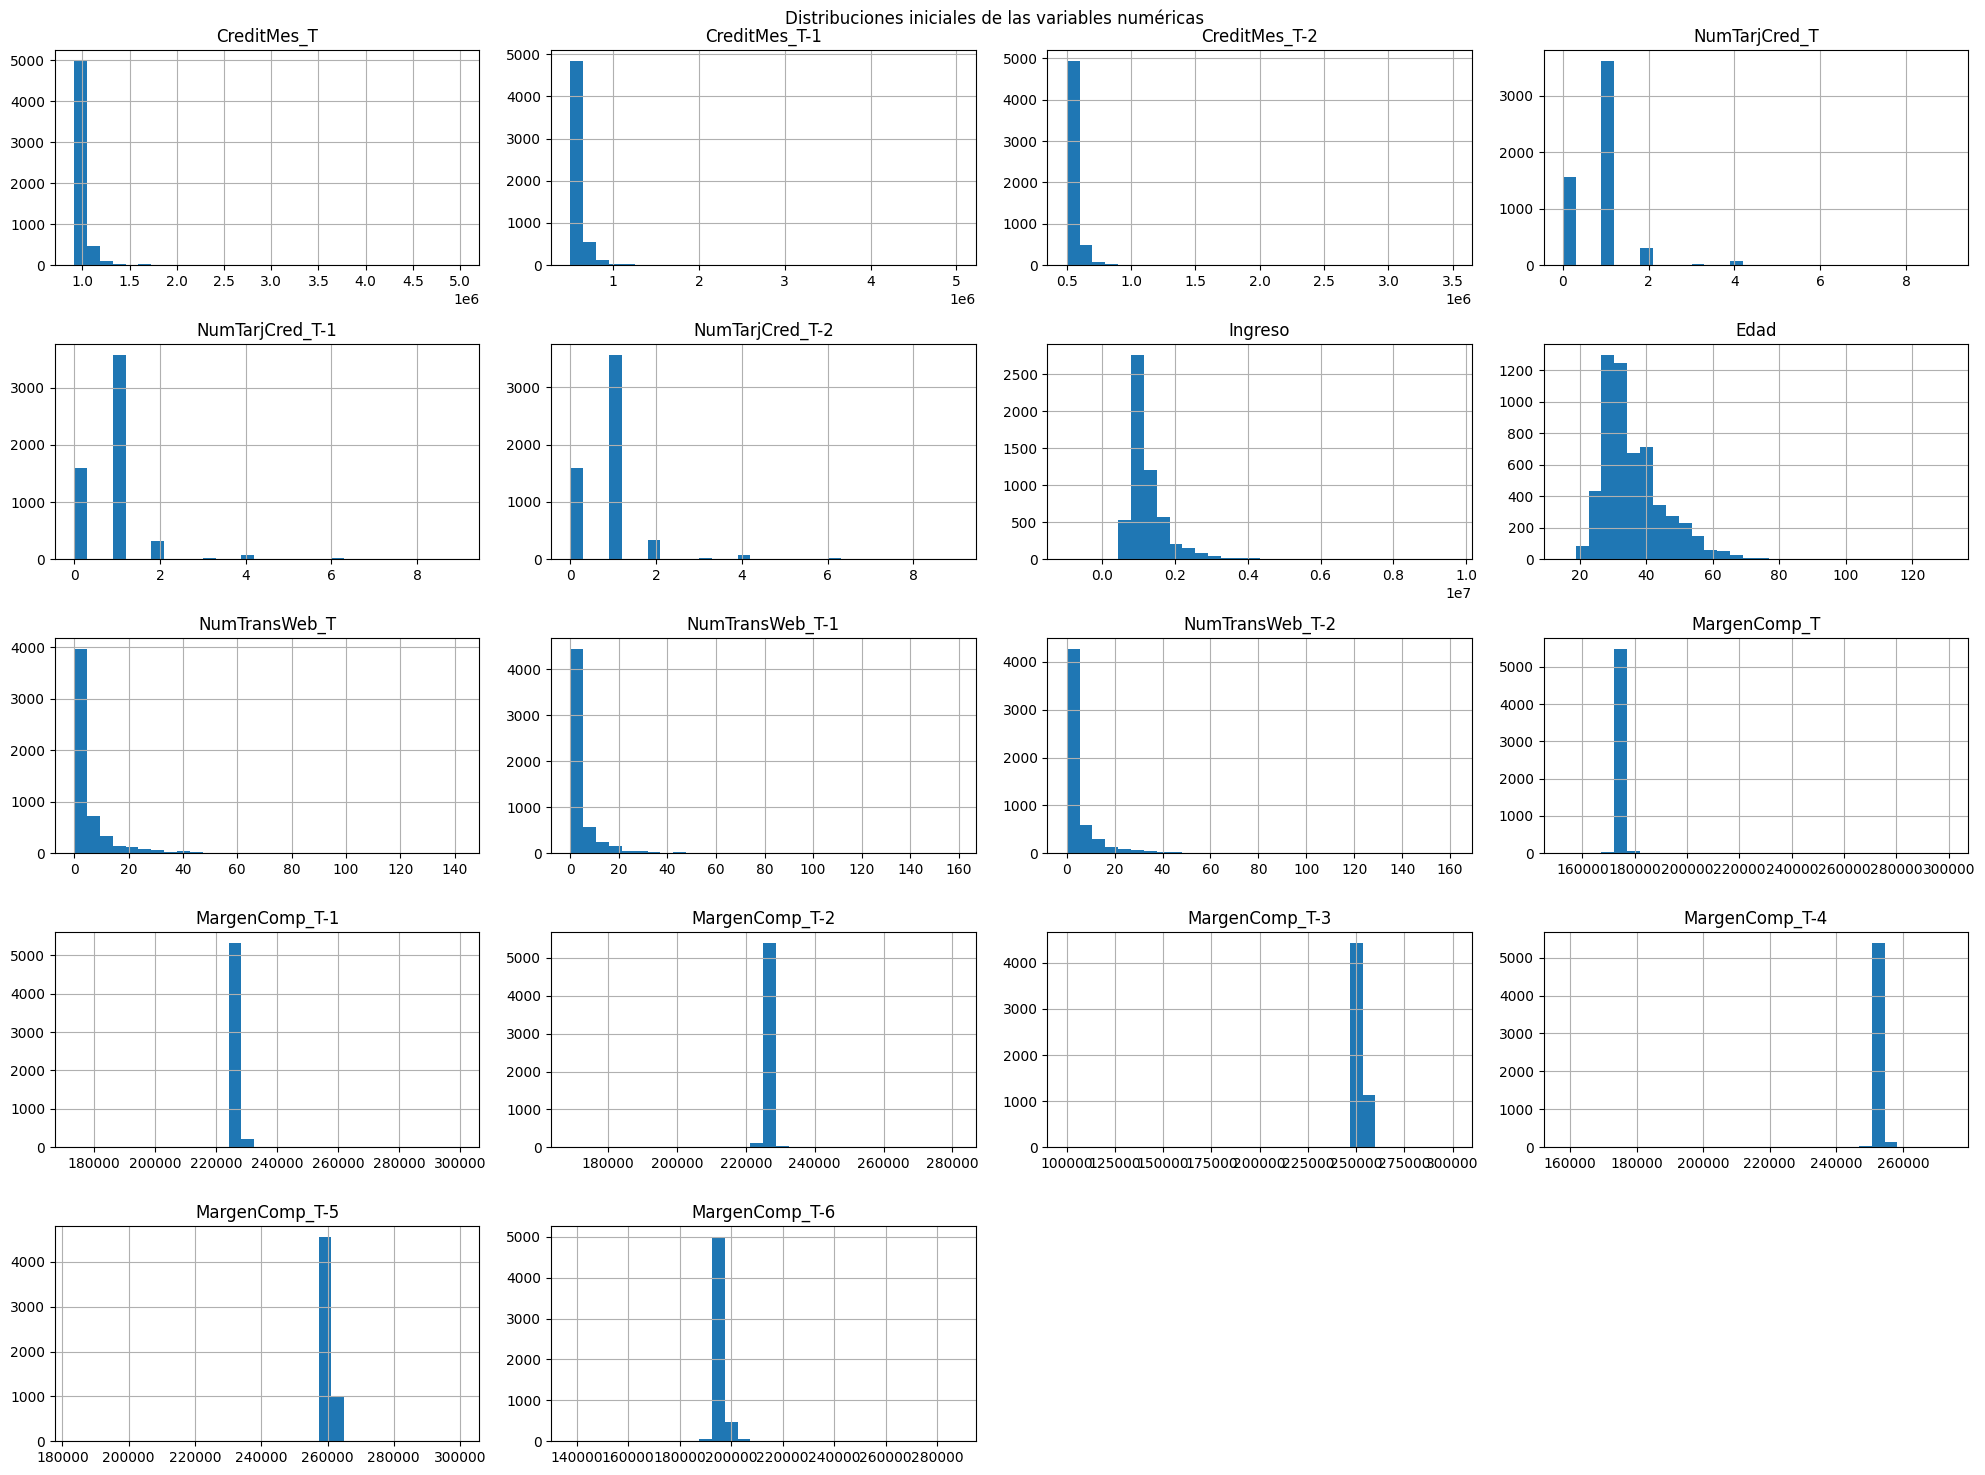

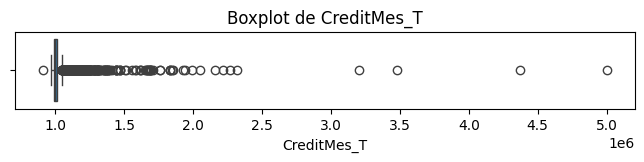

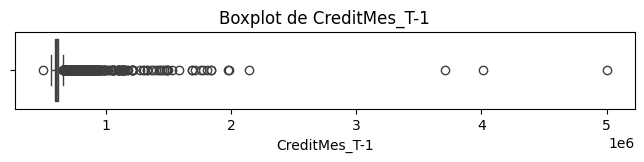

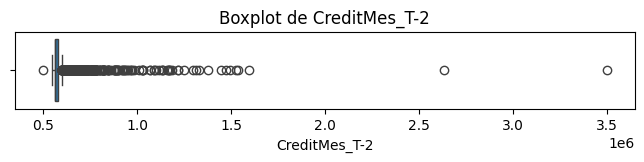

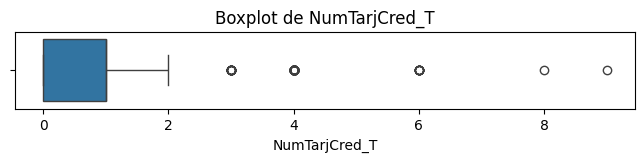

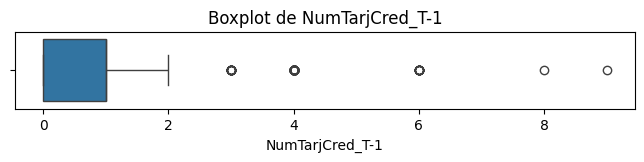

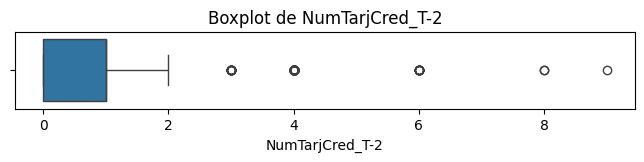

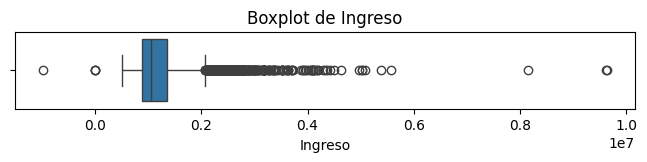

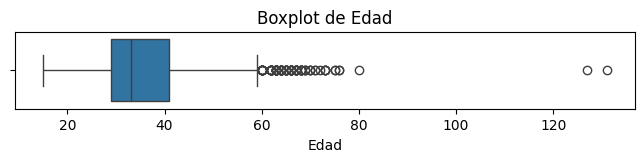

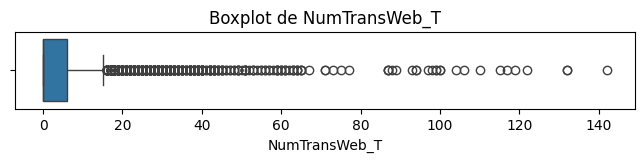

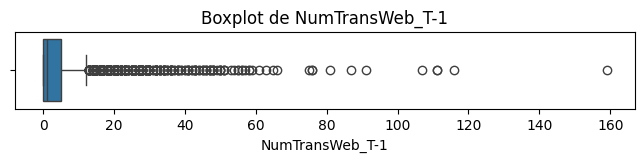

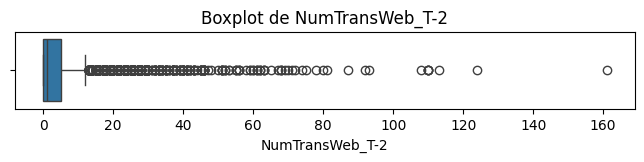

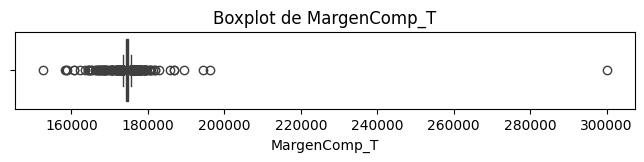

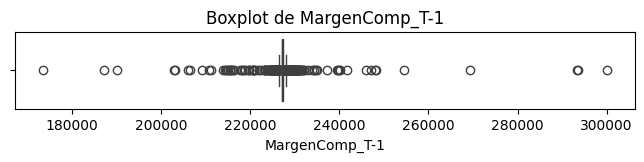

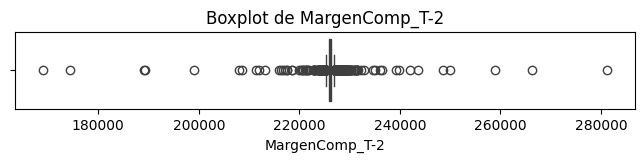

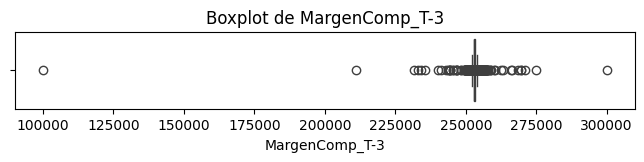

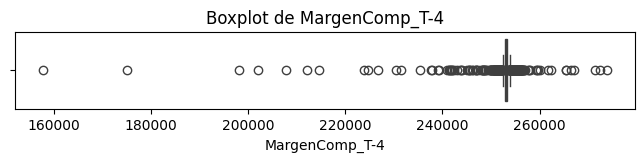

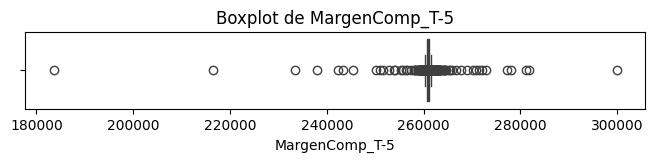

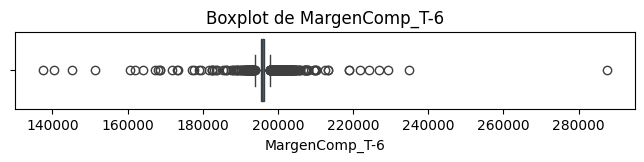

In [ ]:
# PARTE 1: Visualización general y detección de valores extremos

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Histograma general de todas las variables numéricas
data_set.hist(bins=30, figsize=(20, 15))
plt.suptitle("Distribuciones iniciales de las variables numéricas")
plt.tight_layout()
plt.show()

# Boxplots para observar outliers variable por variable
for col in data_set.select_dtypes(include='number').columns:
    plt.figure(figsize=(8, 1))
    sns.boxplot(x=data_set[col])
    plt.title(f'Boxplot de {col}')
    plt.show()


PRIMERO LAS NUMERICAS

In [ ]:
# Ver resumen estadístico de las columnas con NaN (para decidir imputación)
columnas_con_nan = ['CreditMes_T', 'NumTarjCred_T', 'NumTransWeb_T',
                    'NumTransWeb_T-1', 'NumTransWeb_T-2',
                    'MargenComp_T', 'MargenComp_T-1', 'MargenComp_T-2','MargenComp_T-3',
                    'MargenComp_T-4', 'MargenComp_T-5', 'MargenComp_T-6']

data_set[columnas_con_nan].describe().round(2)
matrix = data_set[columnas_con_nan].corr()
print(matrix)

                 CreditMes_T  NumTarjCred_T  NumTransWeb_T  NumTransWeb_T-1  \
CreditMes_T         1.000000       0.056062       0.013311         0.007026   
NumTarjCred_T       0.056062       1.000000       0.056117         0.049242   
NumTransWeb_T       0.013311       0.056117       1.000000         0.780313   
NumTransWeb_T-1     0.007026       0.049242       0.780313         1.000000   
NumTransWeb_T-2     0.014480       0.045609       0.745480         0.793381   
MargenComp_T        0.061043       0.027469       0.017660         0.014207   
MargenComp_T-1      0.067887       0.005479       0.011787        -0.002092   
MargenComp_T-2      0.049736       0.045897       0.009097         0.016022   
MargenComp_T-3      0.033187       0.038881       0.006161         0.010071   
MargenComp_T-4      0.028882       0.006240      -0.006105        -0.006429   
MargenComp_T-5      0.026953       0.011370       0.008296         0.010961   
MargenComp_T-6      0.037821       0.047981       0.

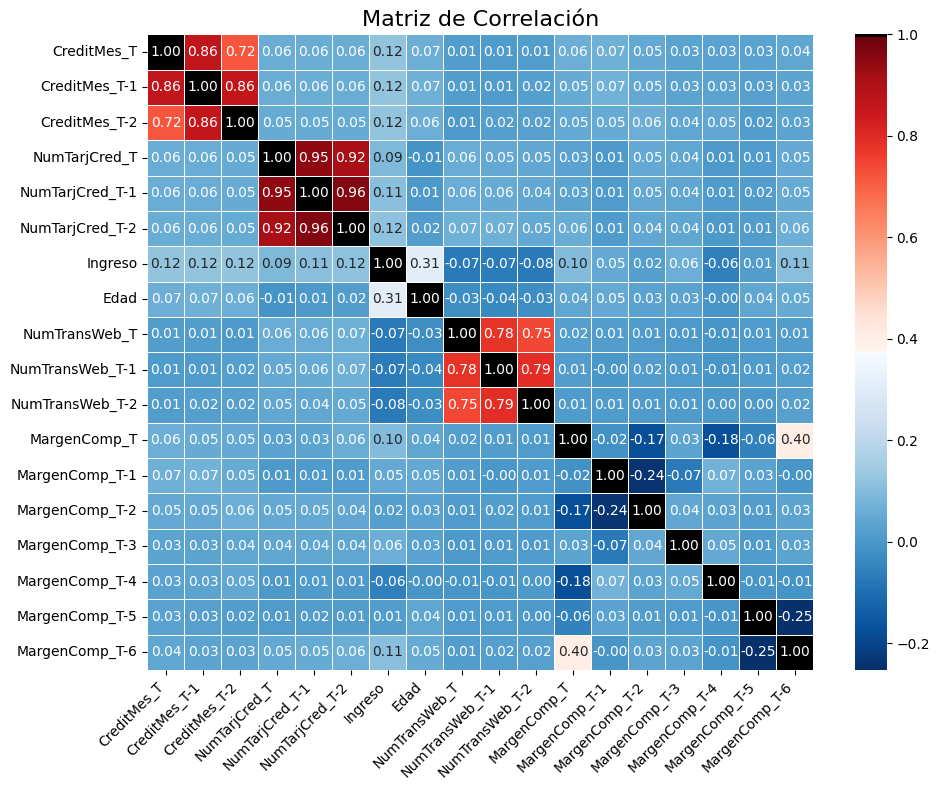

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.colors

# Columnas con NaN (assuming you have 'data_set' defined)
cols = ['CreditMes_T', 'CreditMes_T-1','CreditMes_T-2',
        'NumTarjCred_T', 'NumTarjCred_T-1', 'NumTarjCred_T-2',
        'Ingreso', 'Edad',
        'NumTransWeb_T','NumTransWeb_T-1', 'NumTransWeb_T-2',
        'MargenComp_T', 'MargenComp_T-1', 'MargenComp_T-2',
        'MargenComp_T-3', 'MargenComp_T-4', 'MargenComp_T-5', 'MargenComp_T-6']



# Calcular la matriz de correlación
matrix = data_set[cols].corr()

# Define the custom colormap
def custom_cmap(x):
    if x == 1.0:
        return '#000000'  # Black for the diagonal
    elif x < 0:
        return plt.cm.Blues(abs(x)) # Blue gradient for negative
    elif x > 0:
        return plt.cm.Reds(x)   # Red gradient for positive
    else:
        return '#FFFFFF'  # White for 0

# Create a list of colors using the custom function
colors = [custom_cmap(val) for val in np.linspace(-1, 1, 256)]
cmap = matplotlib.colors.ListedColormap(colors)


# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matrix, annot=True, cmap=cmap, fmt=".2f", linewidths=.5)

# Customize the plot
plt.title('Matriz de Correlación', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 1. Eliminar variable irrelevante por inutilidad
if 'Tiene_Telefono' in data_set.columns:
    data_set = data_set.drop(columns=['Tiene_Telefono'])

# 2. Imputación de valores faltantes

# 2.1 Variables de conteo discreto → rellenar con 0
cols_ceros = ['NumTarjCred_T', 'NumTransWeb_T', 'NumTransWeb_T-1', 'NumTransWeb_T-2']
data_set[cols_ceros] = data_set[cols_ceros].fillna(0)

# 2.2 Variables monetarias → rellenar con mediana
cols_mediana = ['CreditMes_T', 'MargenComp_T', 'MargenComp_T-1', 'MargenComp_T-3',
                'MargenComp_T-4', 'MargenComp_T-5', 'MargenComp_T-6']
for col in cols_mediana:
    mediana = data_set[col].median()
    data_set[col] = data_set[col].fillna(mediana)

# 3. Transformación de variables temporales

# Promedio de crédito
data_set['Prom_Credito'] = data_set[['CreditMes_T', 'CreditMes_T-1', 'CreditMes_T-2']].mean(axis=1)

# Promedio tarjetas
data_set['Prom_Tarjetas'] = data_set[['NumTarjCred_T', 'NumTarjCred_T-1', 'NumTarjCred_T-2']].mean(axis=1)

# Promedio transacciones web
data_set['Prom_TransWeb'] = data_set[['NumTransWeb_T', 'NumTransWeb_T-1', 'NumTransWeb_T-2']].mean(axis=1)

# Margen total 6 meses
cols_margen = [f'MargenComp_T-{i}' for i in range(1, 7)]
data_set['Margen_Total_6m'] = data_set[cols_margen].sum(axis=1)

# 4. Limpieza adicional

# Edad fuera de rango → truncar a [18, 100]
data_set['Edad'] = data_set['Edad'].apply(lambda x: 100 if x > 100 else (x if x >= 18 else 18))

# Ingreso negativo → reemplazo por mediana positiva
mediana_ingreso = data_set[data_set['Ingreso'] > 0]['Ingreso'].median()
data_set['Ingreso'] = data_set['Ingreso'].apply(lambda x: mediana_ingreso if x < 0 else x)

# Tarjetas > 7 → truncar a 7
data_set['NumTarjCred_T'] = data_set['NumTarjCred_T'].apply(lambda x: 7 if x > 7 else x)

# Transacciones web > 150 → truncar a percentil 95
percentil_95_web = np.percentile(data_set['NumTransWeb_T'], 95)
data_set['NumTransWeb_T'] = data_set['NumTransWeb_T'].apply(lambda x: percentil_95_web if x > 150 else x)


In [ ]:
#pequeños ajustes que no quedaron en la parte anterior
# Imputar valores faltantes en NumTarjCred_T-1 como 0
data_set['NumTarjCred_T-1'] = data_set['NumTarjCred_T-1'].fillna(0)

# (Opcional) Recalcular promedio de tarjetas
data_set['Prom_Tarjetas'] = data_set[['NumTarjCred_T', 'NumTarjCred_T-1', 'NumTarjCred_T-2']].mean(axis=1)

Imputación de valores faltantes (NaN) en variables numéricas:
Se detectaron valores nulos en columnas de crédito, número de tarjetas, transacciones web y márgenes. Para tratarlos, se aplicaron distintos criterios:

Variables de conteo discreto (NumTarjCred_T, NumTransWeb_T, etc.) fueron imputadas con 0, considerando que la ausencia de eventos (como transacciones o uso de tarjetas) puede reflejar un comportamiento real del cliente.

Variables de valor monetario continuo (CreditMes_T, MargenComp_T-*) fueron imputadas con su mediana, dado que estas variables presentaban valores extremos que distorsionan la media. Usar la mediana permite mantener la estructura sin generar sesgo.

Transformación de variables promedio y acumuladas:
Se crearon las variables Prom_Credito, Prom_Tarjetas, Prom_TransWeb y Margen_Total_6m para resumir el comportamiento financiero del cliente a lo largo del tiempo, reduciendo ruido individual mensual.

SEGUNDO LAS NO NUMERICAS

In [ ]:
# Revisar valores únicos en las principales variables categóricas
print("▶ NivelEduc:")
print(data_set['NivelEduc'].value_counts(dropna=False), "\n")

print("▶ Genero:")
print(data_set['Genero'].value_counts(dropna=False), "\n")

print("▶ EstCivil:")
print(data_set['EstCivil'].value_counts(dropna=False), "\n")

print("▶ Region:")
print(data_set['Region'].value_counts(dropna=False))


▶ NivelEduc:
NivelEduc
UNI        3627
TEC        1793
MED         107
EST_UNI      75
NaN           3
Name: count, dtype: int64 

▶ Genero:
Genero
M    3895
F    1681
H      29
Name: count, dtype: int64 

▶ EstCivil:
EstCivil
CAS    2960
SOL    2352
DIV     265
VIU      26
NaN       2
Name: count, dtype: int64 

▶ Region:
Region
RM    5605
Name: count, dtype: int64


In [ ]:
# PARTE 3: Limpieza de variables categóricas sin generación de dummies

# 1. NivelEduc → agrupar MED y EST_UNI como 'Otro', y tratar NaN
data_set['NivelEduc_limpio'] = data_set['NivelEduc'].fillna('Desconocido')
data_set['NivelEduc_limpio'] = data_set['NivelEduc_limpio'].replace({'MED': 'Otro', 'EST_UNI': 'Otro'})

# 2. Genero → corregir errores de digitación y NaN
data_set['Genero_limpio'] = data_set['Genero'].replace({'H': 'M'}).fillna('Desconocido')

# 3. EstCivil → agrupar DIV, VIU y NaN como 'Otro'
data_set['EstCivil_limpio'] = data_set['EstCivil'].replace({'DIV': 'Otro', 'VIU': 'Otro'})
data_set['EstCivil_limpio'] = data_set['EstCivil_limpio'].fillna('Otro')

# 4. Region → eliminar porque no tiene variación (solo 'RM')
data_set = data_set.drop(columns=['Region'])

# 5. Eliminar columnas originales sucias (ya fueron reemplazadas por sus versiones limpias)
data_set = data_set.drop(columns=['NivelEduc', 'Genero', 'EstCivil'])


En esta etapa se abordó el tratamiento de las variables categóricas contenidas en la base original: NivelEduc, Genero, EstCivil y Region. El objetivo fue estandarizar sus categorías, corregir errores de codificación, agrupar niveles poco representados y eliminar aquellas columnas que no aportaban valor al análisis.

NivelEduc:
Se reemplazaron los valores ausentes (NaN) por 'Desconocido' y se agruparon niveles con baja frecuencia como 'MED' y 'EST_UNI' bajo la categoría 'Otro'. Esto se realizó para reducir la fragmentación de la variable y facilitar el análisis posterior.

Genero:
Se corrigió la codificación errónea de 'H', que se unificó con 'M' (Masculino), y los valores faltantes fueron imputados con 'Desconocido'. Este tratamiento permitió normalizar esta variable binaria, evitando errores futuros en segmentaciones.

EstCivil:
Se agruparon los estados 'DIV' y 'VIU' en una categoría común llamada 'Otro'. Además, los valores faltantes se imputaron también como 'Otro', bajo el criterio de representar casos atípicos o poco frecuentes dentro de una misma categoría residual.

Region:
La variable fue eliminada debido a que todos los registros presentaban el mismo valor (RM), por lo tanto, no aportaba variabilidad ni información útil para el análisis.

Finalmente, se eliminaron las columnas originales (NivelEduc, Genero, EstCivil, Region) y se conservaron únicamente sus versiones limpias: NivelEduc_limpio, Genero_limpio y EstCivil_limpio.

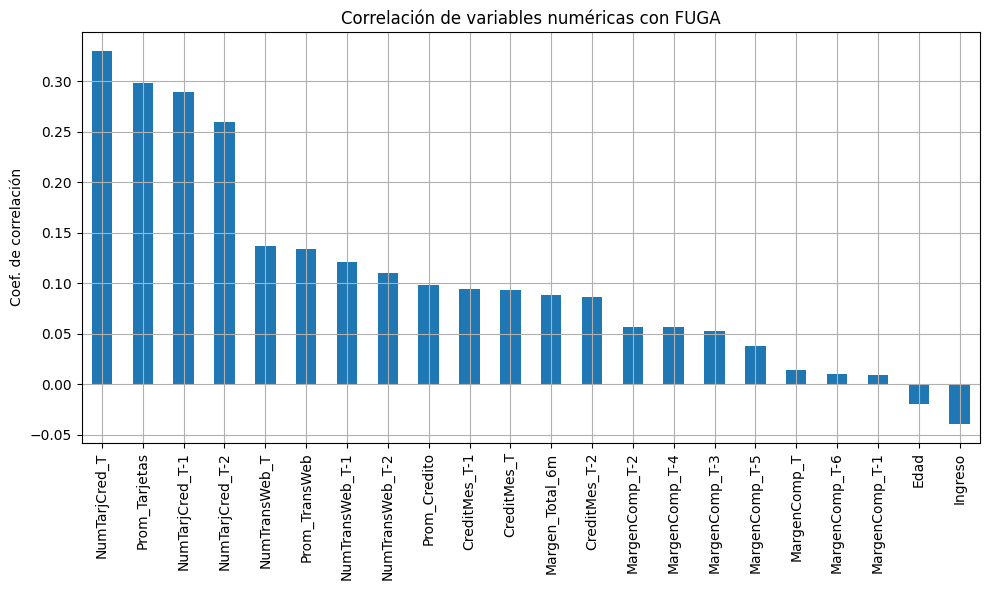

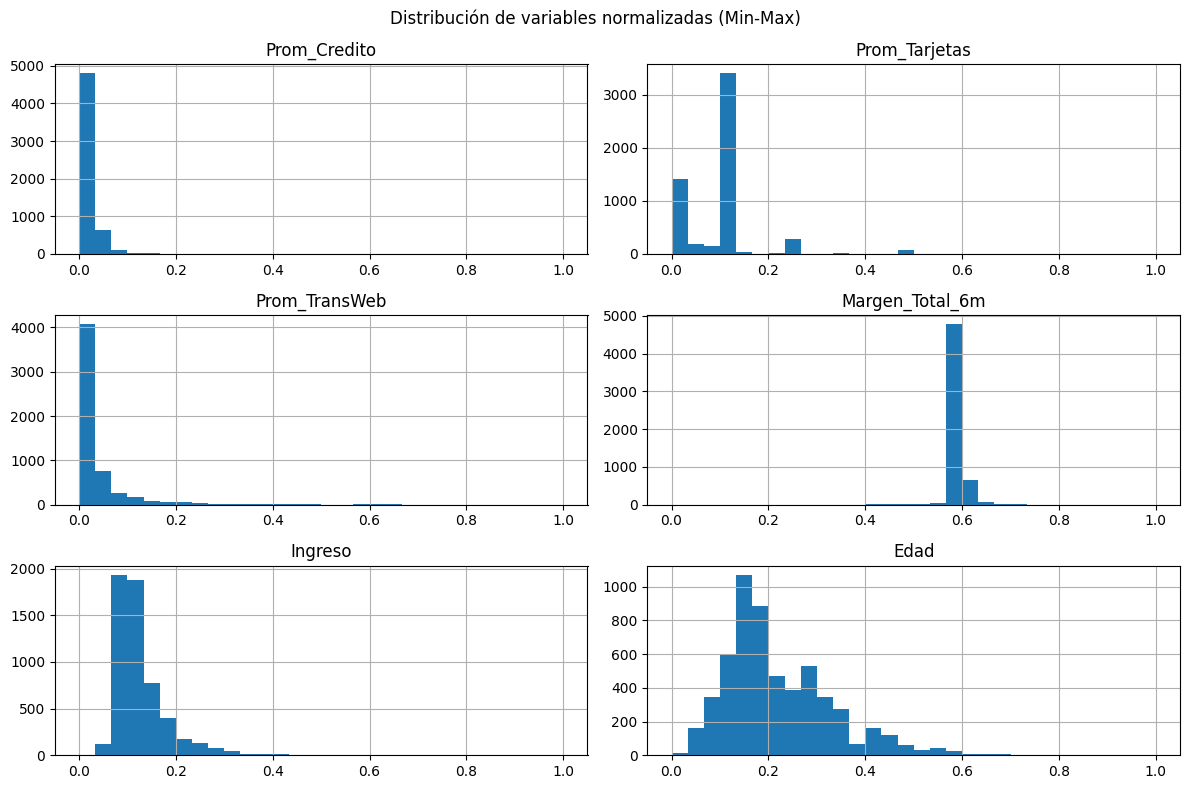

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# 1. Crear variable binaria de fuga
#data_set = pd.get_dummies(data_set, columns = ["FUGA"], drop_first = True)
data_set = pd.get_dummies(data_set, columns = ["FUGA"], drop_first = True)
# 2. Calcular la correlación de todas las variables numéricas con FUGA
correlaciones = data_set.corr(numeric_only=True)['FUGA_NF'].sort_values(ascending=False)

# 3. Visualizar las correlaciones (excluyendo la propia FUGA_BIN)
correlaciones.drop('FUGA_NF').plot(kind='bar', figsize=(10, 6))
plt.title('Correlación de variables numéricas con FUGA')
plt.ylabel('Coef. de correlación')
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Seleccionar columnas numéricas creadas para normalizar
variables_a_normalizar = ['Prom_Credito', 'Prom_Tarjetas', 'Prom_TransWeb', 'Margen_Total_6m', 'Ingreso', 'Edad']

# 5. Normalización Min-Max
scaler = MinMaxScaler()
data_set_normalizado = data_set.copy()
data_set_normalizado[variables_a_normalizar] = scaler.fit_transform(data_set[variables_a_normalizar])

# 6. Visualizar la distribución de las variables normalizadas
data_set_normalizado[variables_a_normalizar].hist(bins=30, figsize=(12, 8))
plt.suptitle("Distribución de variables normalizadas (Min-Max)")
plt.tight_layout()
plt.show()


In [ ]:
# Revisión de datos nulos.
data_set.isnull().sum()

,0
CreditMes_T,0
CreditMes_T-1,0
CreditMes_T-2,0
NumTarjCred_T,0
NumTarjCred_T-1,0
NumTarjCred_T-2,0
Ingreso,0
Edad,0
NumTransWeb_T,0
NumTransWeb_T-1,0


## Dar sentido matemático a variables nominales


In [ ]:
data_set = pd.get_dummies(data_set, columns = ["Telefono"])
data_set = pd.get_dummies(data_set, columns = ["NivelEduc_limpio"], drop_first = True)
data_set = pd.get_dummies(data_set, columns = ["Genero_limpio"],drop_first = True)
data_set = pd.get_dummies(data_set, columns = ["EstCivil_limpio"], drop_first = True)

# Filtros (Selección de atributos)

Los filtros se utilizan para elegir un subconjunto de variables relevantes eliminando las que generan ruido antes de correr los modelos. Veremos tres criterios:

#Variables sesgadas


Se elimina la variable Nivel de educacion ya que es una variable sesgada

In [ ]:

del data_set["NivelEduc_limpio_Otro"]
del data_set["NivelEduc_limpio_TEC"]
del data_set["NivelEduc_limpio_UNI"]


## Inutilidad

Este criterio consiste en descartar las variables muy concentradas dentro de la base de datos.  Para esto calculamos la desviación estándar de las variables:

In [ ]:
data_set.std()

,0
CreditMes_T,115196.843430
CreditMes_T-1,127733.568081
CreditMes_T-2,80016.499402
NumTarjCred_T,0.696804
NumTarjCred_T-1,0.716251
NumTarjCred_T-2,0.728113
Ingreso,561508.677242
Edad,9.127890
NumTransWeb_T,11.328162
NumTransWeb_T-1,8.497848


Descartamos Telefono porque su desviación estándar es 0, es decir, la variable siempre toma el mismo valor.

In [ ]:
del data_set["Telefono_SI"]

## Redundancia

Este criterio consiste en encontrar las variables que están muy correlacionadas entre sí, dejando solo una. Variables redundantes no aportan información nueva. Lo primero es visualizar la matriz de correlaciones bivariadas mediante un *heatmap*:

<Axes: >

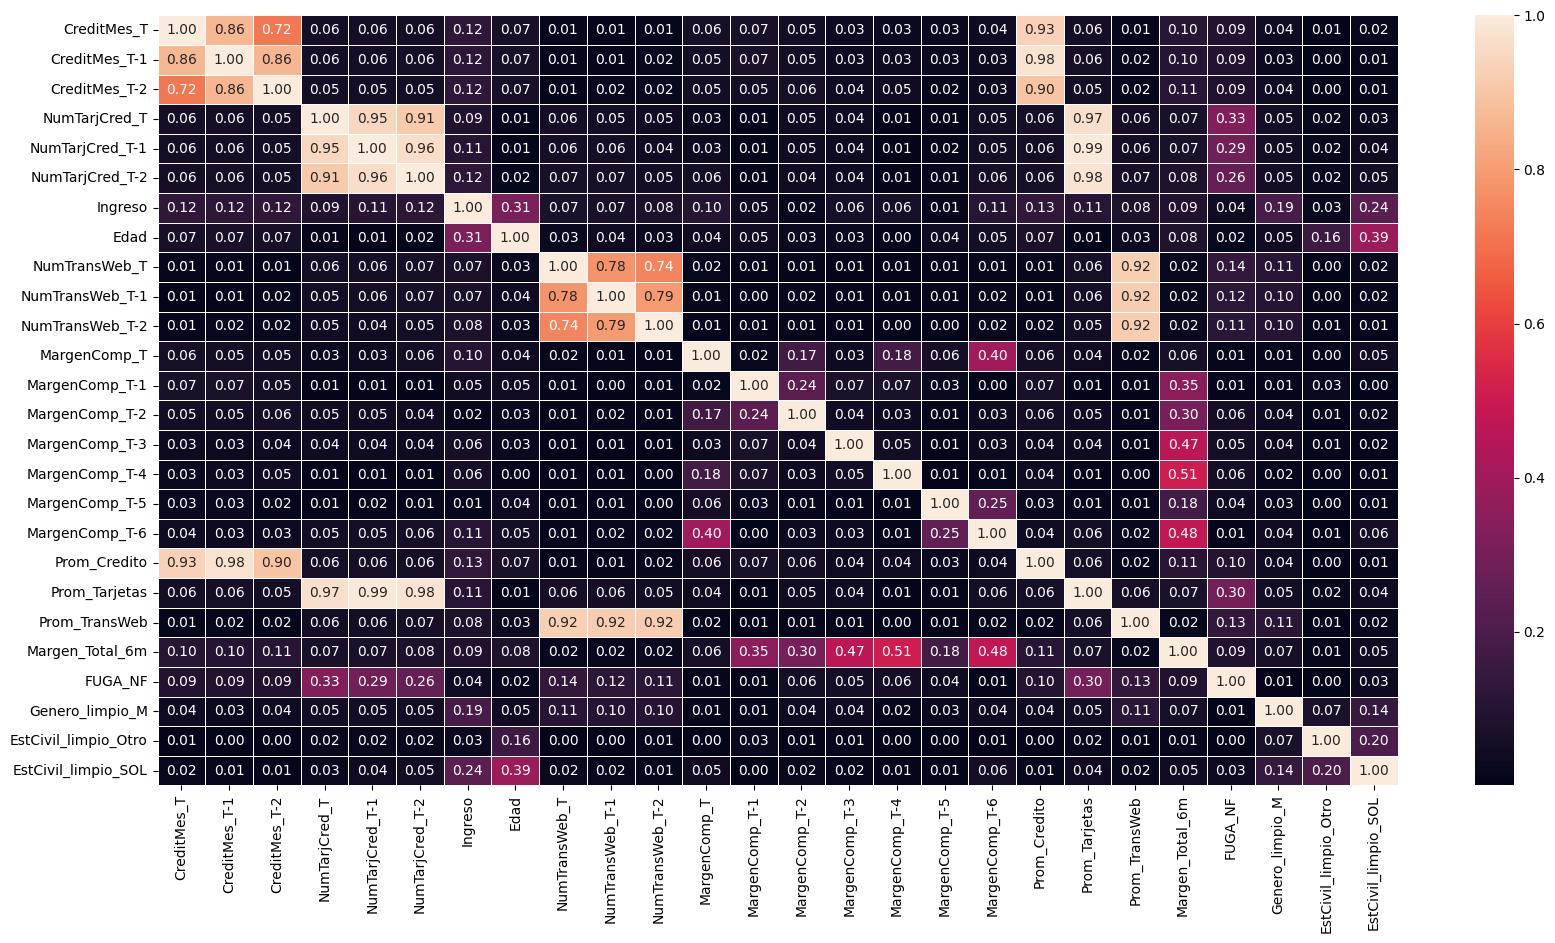

In [ ]:
corrmat = data_set.corr().abs()
f, ax = plt.subplots(figsize=(20, 10))
sn.heatmap(corrmat, annot=True, fmt=".2f", linewidths=.5)

In [ ]:
corrmat.loc["Prom_TransWeb"]

,Prom_TransWeb
CreditMes_T,0.012968
CreditMes_T-1,0.016833
CreditMes_T-2,0.015800
NumTarjCred_T,0.055800
NumTarjCred_T-1,0.057266
NumTarjCred_T-2,0.065665
Ingreso,0.079756
Edad,0.032430
NumTransWeb_T,0.924242
NumTransWeb_T-1,0.919645


In [ ]:
#Test Chi Cuadrado Relevancia NumTransWeb_T, NumTransWeb_T-1 y NumTransWeb_T-2

cut_points = data_set['NumTransWeb_T'].quantile([0, .2, .4, .6, .8, 1]) #el array es como quiero dividir los datos
cut_points = cut_points.drop_duplicates()
NumTansWeb_T_binned = pd.cut(data_set['NumTransWeb_T'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['NumTransWeb_T-1'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
NumTansWeb_T1_binned = pd.cut(data_set['NumTransWeb_T-1'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['NumTransWeb_T-2'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
NumTansWeb_T2_binned = pd.cut(data_set['NumTransWeb_T-2'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['Prom_TransWeb'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
Prom_TransWeb_binned = pd.cut(data_set['Prom_TransWeb'], bins=cut_points, include_lowest=True, duplicates='drop')

from scipy.stats import chi2_contingency
tbl = pd.crosstab(index= NumTansWeb_T_binned,columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=NumTansWeb_T1_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=NumTansWeb_T2_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=Prom_TransWeb_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)

Valor chi cuadrado = 279
P-valor =0.000000
Valor chi cuadrado = 177
P-valor =0.000000
Valor chi cuadrado = 117
P-valor =0.000000
Valor chi cuadrado = 307
P-valor =0.000000


In [ ]:
#Test Chi Cuadrado Relevancia CreditMes_T, CreditMes_T-1 y CreditMes_T-2
from scipy.stats import chi2_contingency
cut_points = data_set['CreditMes_T'].quantile([0, .2, .4, .6, .8, 1]) #el array es como quiero dividir los datos
cut_points = cut_points.drop_duplicates()
CreditMes_T_binned = pd.cut(data_set['CreditMes_T'], bins=cut_points, include_lowest=True, duplicates='drop') # bins puede ser un int tambien con el numero de diviciones en el intervalo y en base a eso lo divide
cut_points = data_set['CreditMes_T-1'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
CreditMes_T1_binned = pd.cut(data_set['CreditMes_T-1'], bins=cut_points, include_lowest=True, duplicates='drop')
cut_points = data_set['CreditMes_T-2'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
CreditMes_T2_binned = pd.cut(data_set['CreditMes_T-2'], bins=cut_points, include_lowest=True, duplicates='drop')
cut_points = data_set['Prom_Credito'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
Prom_Credito_binned = pd.cut(data_set['Prom_Credito'], bins=cut_points, include_lowest=True, duplicates='drop')

tbl = pd.crosstab(index= CreditMes_T_binned,columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=CreditMes_T1_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=CreditMes_T2_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=Prom_Credito_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)

Valor chi cuadrado = 1406
P-valor =0.000000
Valor chi cuadrado = 1155
P-valor =0.000000
Valor chi cuadrado = 978
P-valor =0.000000
Valor chi cuadrado = 1437
P-valor =0.000000


In [ ]:
#Test Chi Cuadrado Relevancia NumTarjCred_T, NumTarjCred_T-1 y NumTarjCred_T-2
from scipy.stats import chi2_contingency
cut_points = data_set['NumTarjCred_T'].quantile([0, .2, .4, .6, .8, 1]) #el array es como quiero dividir los datos
cut_points = cut_points.drop_duplicates()
NumTarjCred_T_binned = pd.cut(data_set['NumTarjCred_T'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['NumTarjCred_T-1'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
NumTarjCred_T1_binned = pd.cut(data_set['NumTarjCred_T-1'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['NumTarjCred_T-2'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
NumTarjCred_T2_binned = pd.cut(data_set['NumTarjCred_T-2'], bins=cut_points, include_lowest=True, duplicates='drop')

cut_points = data_set['Prom_Tarjetas'].quantile([0, .2, .4, .6, .8, 1])
cut_points = cut_points.drop_duplicates()
Prom_Tarjetas_binned = pd.cut(data_set['Prom_Tarjetas'], bins=cut_points, include_lowest=True, duplicates='drop')


tbl = pd.crosstab(index= NumTarjCred_T_binned,columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=NumTarjCred_T1_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=NumTarjCred_T2_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)
tbl = pd.crosstab(index=Prom_Tarjetas_binned, columns=data_set['FUGA_NF'])
stat, p, dof, expected = chi2_contingency(tbl)
print('Valor chi cuadrado = %d' % stat)
print('P-valor =%f' % p)

Valor chi cuadrado = 25
P-valor =0.000000
Valor chi cuadrado = 23
P-valor =0.000002
Valor chi cuadrado = 21
P-valor =0.000004
Valor chi cuadrado = 23
P-valor =0.000001


In [ ]:
del data_set["NumTarjCred_T-1"]
del data_set["NumTarjCred_T-2"]
del data_set["Prom_Tarjetas"]
del data_set["CreditMes_T"]
del data_set["CreditMes_T-1"]
del data_set["CreditMes_T-2"]
del data_set["NumTransWeb_T"]
del data_set["NumTransWeb_T-1"]
del data_set["NumTransWeb_T-2"]

<Axes: >

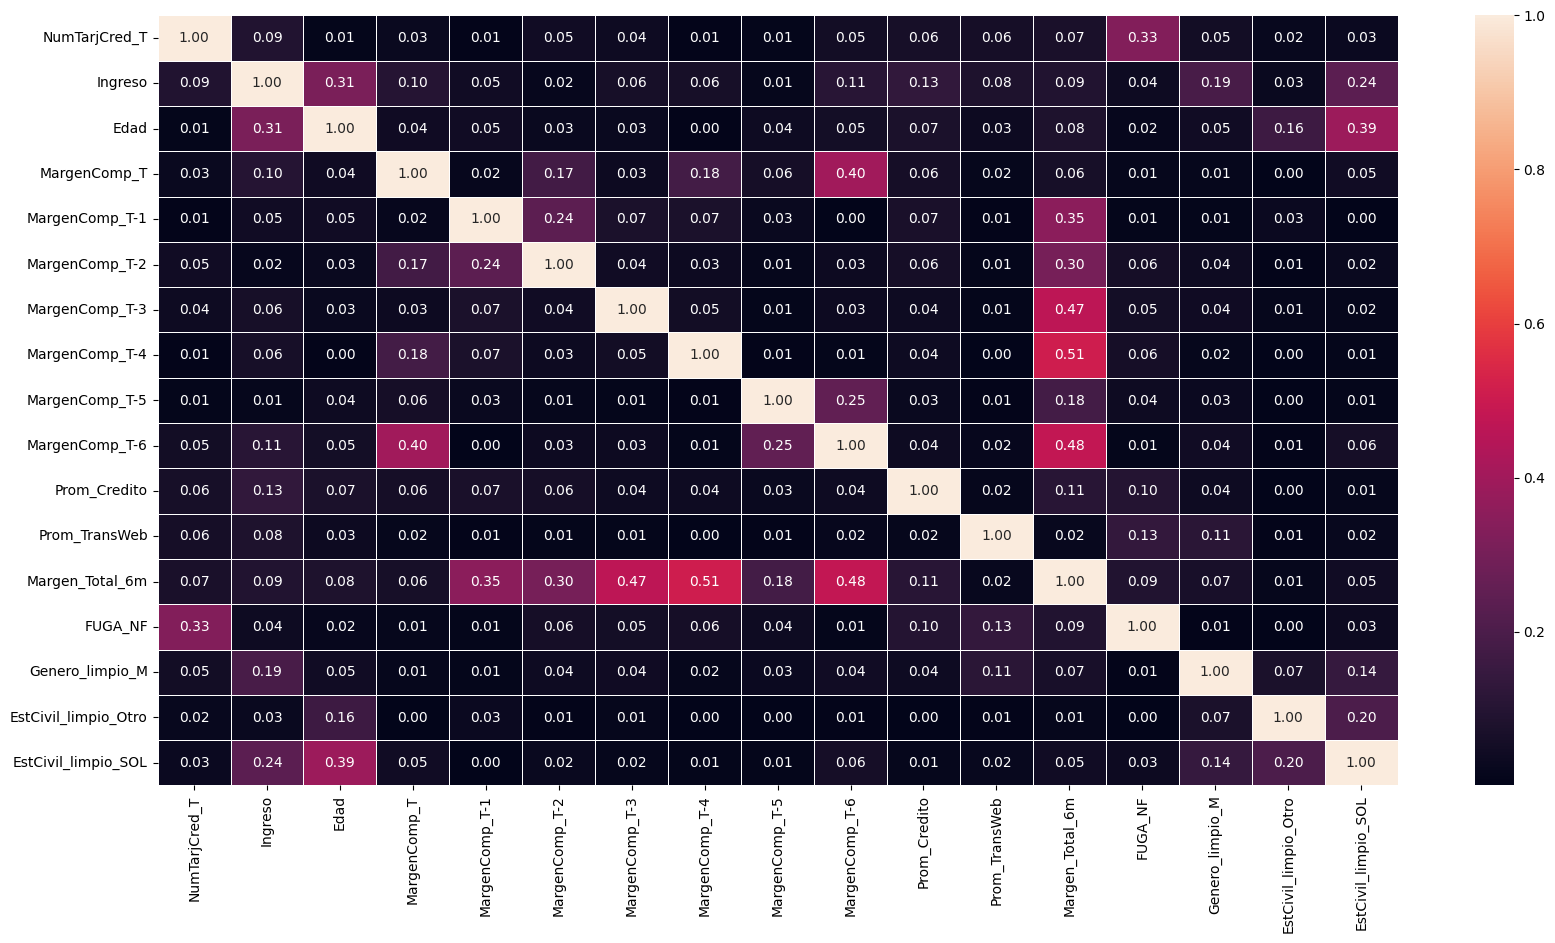

In [ ]:
corrmat = data_set.corr().abs()
f, ax = plt.subplots(figsize=(20, 10))
sn.heatmap(corrmat, annot=True, fmt=".2f", linewidths=.5)

In [ ]:
X = data_set.loc[:, data_set.columns != 'FUGA_NF']
y = data_set.loc[:, data_set.columns == 'FUGA_NF']
X.shape

(5605, 16)

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
np.set_printoptions(suppress=True)


# Selección con todas las variables
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X, y.values.ravel())

# Crear DataFrame con scores y p-valores
results = pd.DataFrame({
    'Feature': X.columns,
    'F_score': selector.scores_,
    'p_value': selector.pvalues_
})

# Filtrar solo variables con p < 0.05
relevant = results[results['p_value'] < 0.05]

# 4. Añadir variable que quieres mantener aunque no sea significativa

# Mostrar solo las variables relevantes
print(relevant)




                Feature     F_score        p_value
0         NumTarjCred_T  683.646945  2.742943e-142
1               Ingreso    8.743129   3.120678e-03
5        MargenComp_T-2   18.027512   2.212572e-05
6        MargenComp_T-3   15.538545   8.182480e-05
7        MargenComp_T-4   17.656142   2.687727e-05
8        MargenComp_T-5    8.159294   4.299873e-03
10         Prom_Credito   54.067812   2.215428e-13
11        Prom_TransWeb  102.283758   7.699454e-24
12      Margen_Total_6m   44.238780   3.182806e-11
15  EstCivil_limpio_SOL    6.508951   1.075962e-02


In [ ]:
del data_set["Edad"]
del data_set["MargenComp_T"]
del data_set["MargenComp_T-1"]
del data_set["MargenComp_T-6"]
del data_set["Genero_limpio_M"]
del data_set["EstCivil_limpio_Otro"]


In [ ]:
FUGA_NF = data_set['FUGA_NF']
scaler = MinMaxScaler()
scaler_data = scaler.fit(data_set)
data_set_scaled = pd.DataFrame(scaler_data.transform(data_set), index=data_set.index, columns=data_set.columns)
data_set_scaled['FUGA_NF'] = FUGA_NF
print(data_set_scaled)

      NumTarjCred_T   Ingreso  MargenComp_T-2  MargenComp_T-3  MargenComp_T-4  \
0          0.285714  0.109056        0.507045          0.7635        0.818762   
1          0.000000  0.086264        0.507045          0.7640        0.819279   
2          0.142857  0.101853        0.481184          0.7642        0.816865   
3          0.142857  0.122376        0.510790          0.7658        0.822901   
4          0.142857  0.090211        0.509898          0.7657        0.820831   
...             ...       ...             ...             ...             ...   
5600       0.000000  0.100965        0.508115          0.7642        0.820141   
5601       0.142857  0.103037        0.514000          0.7676        0.726160   
5602       0.000000  0.088435        0.508472          0.7643        0.820314   
5603       0.000000  0.383640        0.000000          0.7499        0.823245   
5604       0.285714  0.090014        0.508115          0.7642        0.820141   

      MargenComp_T-5  Prom_

In [ ]:
data_set.to_excel('Base_Fuga_preprocesada2.xlsx',index=False)
!cp Base_Fuga_preprocesada2.xlsx "/content/gdrive/MyDrive/Proyecto BA G19/Entrega 3/"

In [ ]:

# Estadística Descriptiva
data_set.describe(include='all').round(1)